# 09 — Train, evaluate, generate

**Chapter 2** · suggested time: 35 min · CPU: ≈ 2 to 4 min of training (start the cell at the beginning of the explanation) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/09_training_and_evaluation.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

**By the end of this notebook you will be able to:**
1. write and explain the full training loop, with regular evaluation;
2. read a train / validation curve and spot **overfitting**;
3. evaluate a language model other than "by eye": loss, perplexity, loss **per position**, comparison with the bigram;
4. look at **what the attention heads have learned**;
5. generate text and tune the **temperature**.

In [1]:
# On Google Colab: fetch the course repo (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the minigpt.py file, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)
import time

CORPUS = "shakespeare"        # then try "kaamelott" or "plato"
text, tok, train_data, val_data = minigpt.prepare_data(CORPUS)
V = tok.vocab_size
print(f"{CORPUS}: V = {V}, train = {len(train_data):,}, val = {len(val_data):,}")

PyTorch 2.15.0+cu132 | device: cpu
shakespeare: V = 65, train = 1,003,854, val = 111,540


## 1. The hyperparameters

| Name | Value | Role |
|---|---|---|
| `batch_size` (B) | 32 | sequences per step |
| `block_size` (T) | 64 | maximum context length |
| `n_embd` (C) | 64 | width of the residual stream |
| `n_head` | 4 | heads per block (size 16 each) |
| `n_layer` | 4 | number of blocks |
| `dropout` | 0.1 | regularization |
| `learning_rate` | 1e-3 | AdamW (small model → larger lr than Karpathy's 3e-4) |
| `max_iters` | 2000 | number of steps |

These values are chosen to run **on a laptop without a GPU** in a few minutes. Karpathy, on a GPU, uses `B=64, T=256, C=384, n_head=6, n_layer=6` (≈ 10M parameters) and reaches a validation loss of ≈ 1.48.

In [3]:
batch_size, block_size = 32, 64
n_embd, n_head, n_layer, dropout = 64, 4, 4, 0.1
learning_rate, max_iters = 1e-3, 2000
eval_interval, eval_iters = 200, 20

torch.manual_seed(1337)
model = minigpt.GPTLanguageModel(V, block_size, n_embd, n_head, n_layer, dropout).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
print(f"{minigpt.count_parameters(model):,} parameters")

211,777 parameters


## 2. The training loop

![Training loop](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/09_training_loop.png)

This is **the same loop as for the bigram** (notebook 02). Only one new thing: every `eval_interval` iterations, we call `estimate_loss`, which:
- switches the model to `eval()` (dropout off) and disables gradient computation (`@torch.no_grad()`);
- averages the loss over `eval_iters` batches, for **train** and for **val** (a single batch loss is too noisy, notebook 03);
- switches the model back to `train()`.

In [4]:
history = {"step": [], "train": [], "val": []}
start = time.time()
for it in range(max_iters):
    if it % eval_interval == 0 or it == max_iters - 1:
        losses = minigpt.estimate_loss(model, train_data, val_data, batch_size, block_size, eval_iters, device)
        for k in ("train", "val"):
            history[k].append(losses[k])
        history["step"].append(it)
        print(f"step {it:4d} | train {losses['train']:.3f} | val {losses['val']:.3f} | {time.time() - start:5.0f} s")

    xb, yb = minigpt.get_batch(train_data, batch_size, block_size, device)   # 1. batch
    logits, loss = model(xb, yb)                                             # 2. forward
    optimizer.zero_grad(set_to_none=True)                                    # 3. clear
    loss.backward()                                                          # 4. gradients
    optimizer.step()                                                         # 5. update
print(f"Training finished in {time.time() - start:.0f} s")

step    0 | train 4.339 | val 4.348 |     0 s


step  200 | train 2.490 | val 2.485 |    10 s


step  400 | train 2.326 | val 2.331 |    19 s


step  600 | train 2.191 | val 2.210 |    29 s


step  800 | train 2.090 | val 2.117 |    38 s


step 1000 | train 2.029 | val 2.067 |    47 s


step 1200 | train 1.947 | val 2.020 |    56 s


step 1400 | train 1.884 | val 1.964 |    66 s


step 1600 | train 1.861 | val 1.940 |    75 s


step 1800 | train 1.799 | val 1.905 |    85 s


step 1999 | train 1.773 | val 1.910 |    94 s
Training finished in 94 s


## 3. Reading the learning curves

Reference lines to put on the plot:
- **uniform** `log V`: the model that knows nothing;
- **best possible bigram** (counts from chapter 1): what you can do **without context**.

Everything below the bigram line is due to **context**, and therefore to attention.

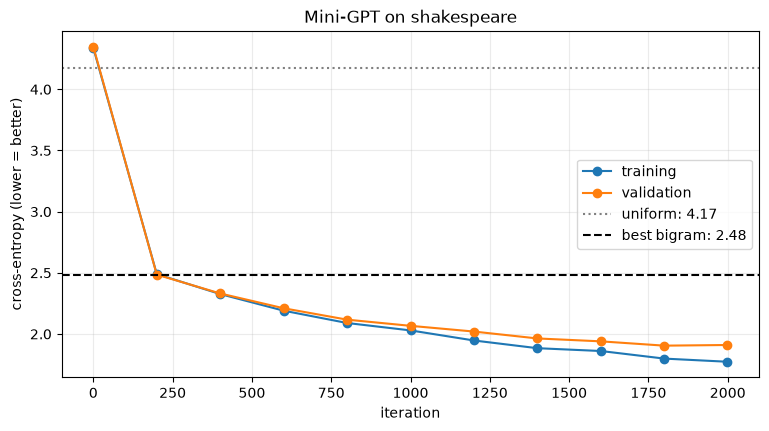

final val: 1.910 | bigram: 2.482 | gain from context: 0.572


In [5]:
# Best possible bigram: counts + smoothing (chapter 1)
N = torch.ones(V, V)
N.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
P = N / N.sum(1, keepdim=True)
bigram_loss = -P[val_data[:-1], val_data[1:]].log().mean().item()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history["step"], history["train"], marker="o", label="training")
ax.plot(history["step"], history["val"], marker="o", label="validation")
ax.axhline(math.log(V), color="gray", ls=":", label=f"uniform: {math.log(V):.2f}")
ax.axhline(bigram_loss, color="black", ls="--", label=f"best bigram: {bigram_loss:.2f}")
ax.set_xlabel("iteration"); ax.set_ylabel("cross-entropy (lower = better)")
ax.set_title(f"Mini-GPT on {CORPUS}"); ax.legend(); ax.grid(alpha=.25); plt.show()
print(f"final val: {history['val'][-1]:.3f} | bigram: {bigram_loss:.3f} | gain from context: {bigram_loss - history['val'][-1]:.3f}")

**How to interpret it:**
- **train ↓ and val ↓ together**: the model is learning regularities that generalize. It is not done: more steps or a bigger model would do better.
- **train ↓ but val ↑**: **overfitting**: the model recites its corpus instead of extracting rules from it.
- **Small train/val gap** here: with 1M characters and 200,000 parameters, the model is far from being able to memorize everything.

## 4. Translating the loss: perplexity

The loss is an average of $-\log p$. Its exponential, the **perplexity**, can be read as "the number of characters the model is hesitating between, on average":

$$\text{perplexity} = e^{\mathcal{L}}$$

In [6]:
for name, L in [("uniform", math.log(V)), ("bigram", bigram_loss), ("mini-GPT", history["val"][-1])]:
    print(f"{name:10s} loss {L:.3f} -> perplexity {math.exp(L):5.1f} characters")

uniform    loss 4.174 -> perplexity  65.0 characters
bigram     loss 2.482 -> perplexity  12.0 characters
mini-GPT   loss 1.910 -> perplexity   6.8 characters


## 5. Does the model really use the context? Loss per position

At position `t` of a window, the model has seen `t + 1` characters. If it exploits the context, its loss should **go down with `t`**. The bigram, on the other hand, has the same loss everywhere.

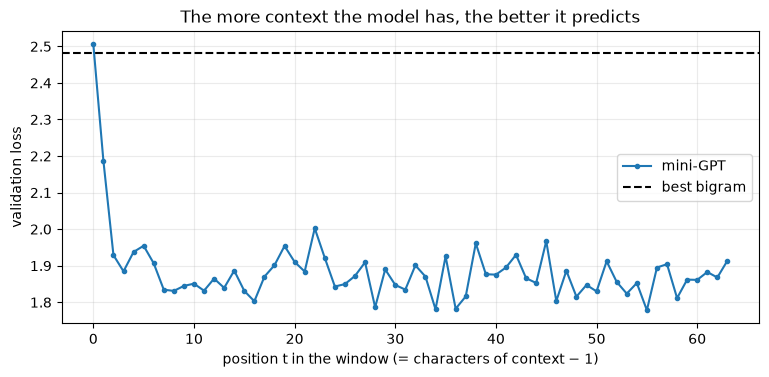

position 0: 2.51 | position 10: 1.85 | position 63: 1.91


In [7]:
@torch.no_grad()
def loss_per_position(model, n_batches=20):
    model.eval()
    total = torch.zeros(block_size)
    for _ in range(n_batches):
        xb, yb = minigpt.get_batch(val_data, 64, block_size, device)
        logits, _ = model(xb)
        l = F.cross_entropy(logits.transpose(1, 2), yb, reduction="none")   # (B, T): one loss per position
        total += l.mean(0).cpu()
    model.train()
    return total / n_batches

lp = loss_per_position(model)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(block_size), lp, marker=".", label="mini-GPT")
ax.axhline(bigram_loss, color="black", ls="--", label="best bigram")
ax.set_xlabel("position t in the window (= characters of context − 1)"); ax.set_ylabel("validation loss")
ax.set_title("The more context the model has, the better it predicts"); ax.legend(); ax.grid(alpha=.25); plt.show()
print(f"position 0: {lp[0]:.2f} | position 10: {lp[10]:.2f} | position {block_size - 1}: {lp[-1]:.2f}")

At position 0, the mini-GPT has only one character: it does about as well as a bigram. With just a few characters of context, it does **clearly better**. This is the numerical proof that attention is useful.

## 6. What have the attention heads learned?

Let's recompute the attention weights of each head on a validation excerpt. Each row = a position that "looks"; each column = a position being looked at.

'rina, this I know,\nShe is no'


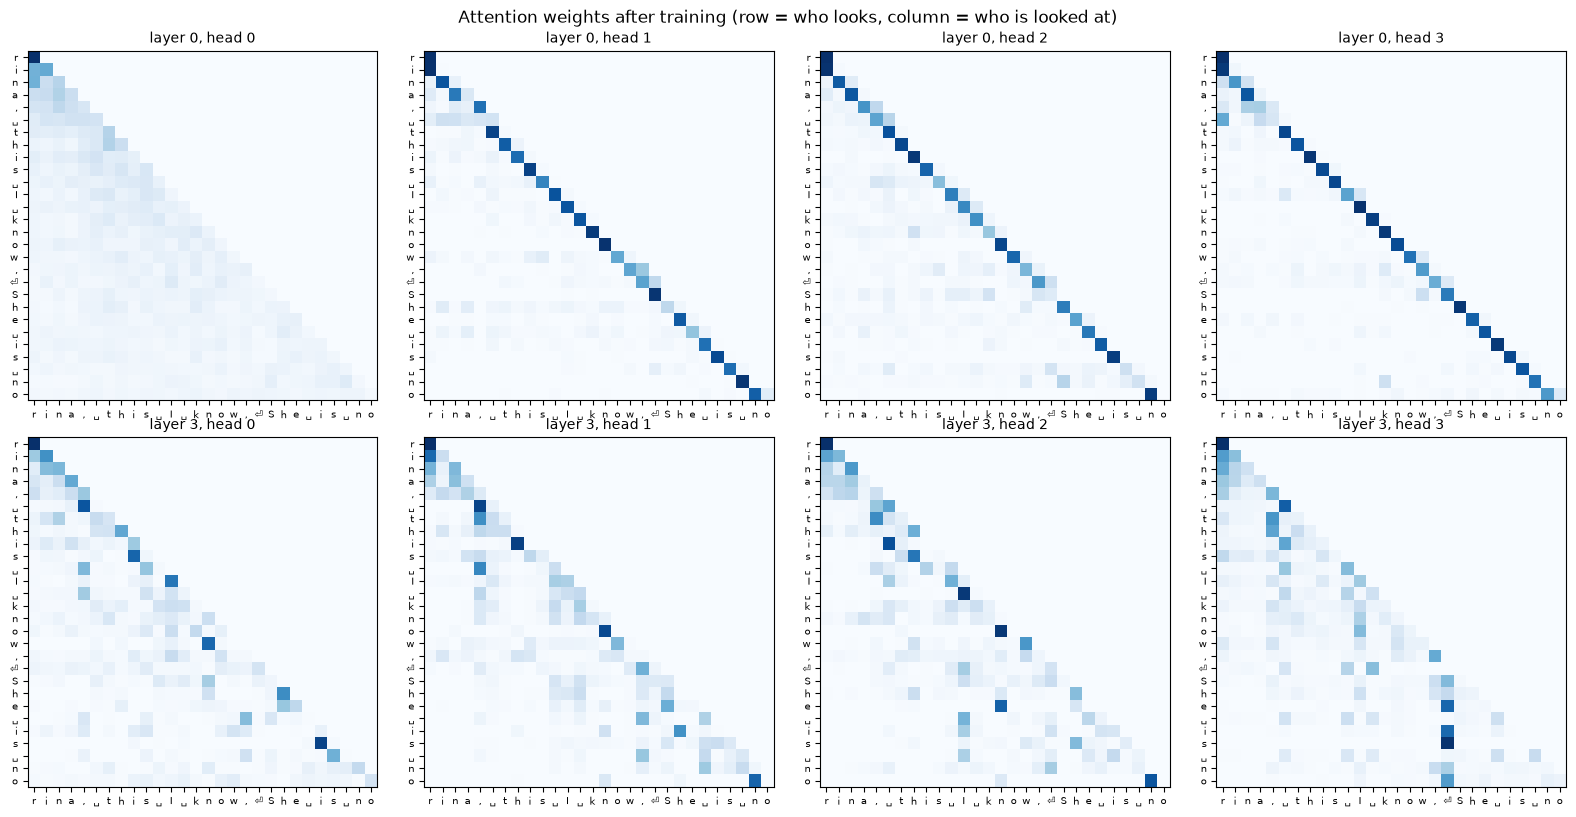

In [8]:
@torch.no_grad()
def attention_weights(model, idx, layer):
    """Weights (n_head, T, T) of the requested layer, for a sequence idx of shape (1, T)."""
    model.eval()
    captured = {}
    h = model.blocks[layer].ln1.register_forward_hook(lambda m, i, o: captured.setdefault("x", o))
    model(idx); h.remove(); model.train()
    x, T = captured["x"], idx.shape[1]
    weights = []
    for head in model.blocks[layer].sa.heads:
        w = head.query(x) @ head.key(x).transpose(-2, -1) * head.key.out_features ** -0.5
        w = w.masked_fill(head.tril[:T, :T] == 0, float("-inf"))
        weights.append(F.softmax(w, dim=-1)[0].cpu())
    return torch.stack(weights)

excerpt = val_data[1000:1028].unsqueeze(0).to(device)
letters = [{"\n": "⏎", " ": "␣"}.get(c, c) for c in tok.decode(excerpt[0])]
print(repr(tok.decode(excerpt[0])))
fig, axes = plt.subplots(2, n_head, figsize=(4 * n_head, 8.2))
for r, layer in enumerate([0, n_layer - 1]):
    W = attention_weights(model, excerpt, layer)
    for h in range(n_head):
        ax = axes[r, h]
        ax.imshow(W[h], cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(letters)), letters, fontsize=7); ax.set_yticks(range(len(letters)), letters, fontsize=7)
        ax.set_title(f"layer {layer}, head {h}", fontsize=10)
fig.suptitle("Attention weights after training (row = who looks, column = who is looked at)")
plt.tight_layout(); plt.show()

**What to look for:**
- the **diagonal**: the head mostly looks at the **current** character (common in the first layer: it copies the character's identity into another "form");
- a **shifted diagonal**: the head looks at the **previous** character (like the head built by hand in notebook 05);
- dark columns on **spaces** or **line breaks**: the head finds the **start of the current word** or line;
- more **diffuse** heads: they average over a wide past (the general "style").

The heads are not programmed: these specializations **emerge** from gradient descent.

## 7. Generating text

### The trained model

In [9]:
model.eval()
torch.manual_seed(42)
start = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long, device=device)
print(tok.decode(model.generate(start, max_new_tokens=400)[0]))



KIDY LEONCE:
Cay the my consure, on annow no fe thou fear heed lams,
To dreath be to our ungule sead, that is u
ceavie them couse to hing the how bear?

ICINGIA:
O he devannot hear, thoug.

POMIO, but Wellow, thee husuedon'd
Mentencelf, but are to ne this mough wer
seeque.

DUKINGARENT:
The ancomb word thour fasce's of I to him.

First feartent:
Sthis hall stemant mering; o-hightor, the down thei


Compared with the bigram from notebook 02: **real** or plausible **words**, **speaker names in capitals followed by `:`**, lines of dialogue separated by blank lines. Overall meaning is still missing: 200,000 parameters and 64 characters of context is very little.

### Temperature

Before the softmax, we can **divide the logits** by a temperature $\tau$:
- $\tau < 1$: a **sharper** distribution → safer, more repetitive text;
- $\tau = 1$: the learned distribution;
- $\tau > 1$: a **flatter** distribution → more creative text… and more mistakes.

In [10]:
for tau in [0.5, 1.0, 1.5]:
    torch.manual_seed(42)
    print(f"--- temperature {tau} ---")
    print(tok.decode(model.generate(start, max_new_tokens=200, temperature=tau)[0]))
    print()
model.train();

--- temperature 0.5 ---




AUDY LEONCE:
The the my come and the and the father the and so life,
The reave the man the greatent.

First Mar
And is the mentleart the but lead be the fand he sue.


Second CLAUTESTER:
O hear and m

--- temperature 1.0 ---




KIDY LEONCE:
Cay the my consure, on annow no fe thou fear heed lams,
To dreath be to our ungule sead, that is u
ceavie them couse to hing the how bear?

ICINGIA:
O he devannot hear, thoug.

POMIO, bu

--- temperature 1.5 ---




KIDY LY GERCHARD:
we my chard'd, Sooldney noc. Hove eread Edword magry!

KISS:
We that'G ungnly sea
uttion.

Pu

COMEAM Seme:
He:
I'll nobleflencil! Mebough-chos neer devavn if Gic,
Thoug. Whatic, bu



## 8. Experiments to try

Change **only one** parameter at a time and compare the **validation** loss (not the quality "by eye"):

| Experiment | Question |
|---|---|
| `n_layer = 1` then `n_layer = 6` | does depth help for the same number of steps? |
| `n_head = 1` then `n_head = 8` (with `n_embd = 64`) | are several heads better than one big one? |
| `block_size = 8` then `128` | look at the **loss per position** curve |
| `CORPUS = "kaamelott"` | same settings, lines in French: can you recognize the characters? |
| `dropout = 0.0` vs `0.2` | does the gap between train and val change? |
| `CORPUS = "plato"` | same model, another language: what does it generate? |
| `optimizer = torch.optim.SGD(..., lr=1e-3)` | what happens to training (notebook 02)? |

## 9. Chapter summary

| Step | What each position can do | Key shape | Notebook |
|---|---|---|---|
| Bigram | use the current character | logits `(B, T, V)` | 02, 03 |
| Cumulative average | receive a uniform average of the past | `(B, T, C)` | 05 |
| Self-attention | **choose** the useful positions (Q·K) and retrieve V | weights `(B, T, T)` | 05 |
| Multi-head | run several searches in parallel | concat `(B, T, C)` | 05 |
| FeedForward | process the received information locally | `(B, T, 4C)` → `(B, T, C)` | 06 |
| Blocks + residuals + LN | stack without losing the gradient | stream `(B, T, C)` | 07 |
| `lm_head` | produce one score per character | `(B, T, V)` | 08 |

**The problem has not changed since chapter 1:** predict the next character, with the same loss (cross-entropy) and the same loop (forward, backward, step). Only the way the logits are produced has changed.

**Check your understanding**
1. Why does `estimate_loss` put the model in `eval()`?
2. What does a perplexity of 6 mean?
3. Why is the loss at position 0 close to the bigram's?
4. If the validation loss went back up while the training loss kept going down, what would you do?
5. Why judge a model on its validation loss rather than on a generated text?

### References
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) and his code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) — the "training" and "scaling up the model" parts.
- A. Karpathy, [nanoGPT](https://github.com/karpathy/nanoGPT) — training GPT-2 on OpenWebText.
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), §5.2 (capacity, overfitting and underfitting) and §7.8 (*early stopping*).
- A. Holtzman et al., [*The Curious Case of Neural Text Degeneration*](https://arxiv.org/abs/1904.09751), ICLR 2020 — temperature and sampling strategies.
- J. Kaplan et al., [*Scaling Laws for Neural Language Models*](https://arxiv.org/abs/2001.08361), 2020 — how the loss depends on model and data size.